In [1]:
# Root filesystem /tmp is full; keep temporary files on the larger /data volume.
import os
os.makedirs("/data/susanket/tmp", exist_ok=True)
os.environ["TMPDIR"] = "/data/susanket/tmp"

import io
import sys
import tqdm
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
import torch
import torch.nn.functional as F
from torchvision import transforms
from transformers import AutoTokenizer
import matplotlib.pyplot as plt

# Add your project src directory
sys.path.append(r"/home/susanket/esri-vlm/src")
from model import CLIP, build_model
from main import CLIPLightningModule

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

/data/susanket/conda/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: cuda


In [2]:
CKPT_PATH = "/home/susanket/esri-vlm/dujvcqom/checkpoints/epoch=7-step=47256.ckpt"  # Update path

ckpt = torch.load(CKPT_PATH, map_location=device, weights_only=False)

if "hyper_parameters" in ckpt:
    # Clean up non-serializable or unnecessary hyperparameters
    for hp_key in ["eval_downstream", "air_temp_data_path", "election_data_path", "_instantiator"]:
        ckpt["hyper_parameters"].pop(hp_key, None)

    model_hp = dict(ckpt["hyper_parameters"])
    model_hp["load_text_backbone"] = True  # eval encodes raw text queries with Qwen
    lightning_model = CLIPLightningModule(**model_hp).to(device)
    lightning_model.load_state_dict(ckpt["state_dict"])
    lightning_model.eval()
    model = lightning_model.model
    tokenizer = lightning_model.tokenizer
else:
    model = build_model(ckpt["state_dict"]).to(device)
    tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen3-Embedding-0.6B", padding_side="left")

model = model.to(device)
model.eval()

# Handle DINOv2 backbone if feature extraction is required
dino_backbone = None
if getattr(model.visual, "precomputed", False):
    from model import DINOV2_REPO
    try:
        dino_backbone = torch.hub.load(DINOV2_REPO, model.visual.model_name, trust_repo=True)
    except TypeError:
        dino_backbone = torch.hub.load(DINOV2_REPO, model.visual.model_name)
    dino_backbone.eval().to(device)

print("Model successfully loaded!")

Loading weights: 100%|██████████| 310/310 [00:00<00:00, 8884.17it/s]
Using cache found in /home/susanket/.cache/torch/hub/facebookresearch_dinov2_main
/home/susanket/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/home/susanket/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/home/susanket/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Model successfully loaded!


In [3]:
PARQUET_PATH = "/data/susanket/vlm/images3/image-00.parquet"  # Update path
IMAGE_COLUMN = "image_bytes"  # Column name containing raw image bytes or dict with 'bytes'

df = pd.read_parquet(PARQUET_PATH).sample(10_000)
print(f"Loaded {len(df)} samples from {PARQUET_PATH}")

image_transform = transforms.Compose([
    transforms.Resize(224, interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

def decode_and_transform(raw_image_data):
    """Helper to handle bytes directly or HuggingFace Datasets dict format."""
    if isinstance(raw_image_data, dict) and "bytes" in raw_image_data:
        raw_bytes = raw_image_data["bytes"]
    else:
        raw_bytes = raw_image_data

    try:
        img = Image.open(io.BytesIO(raw_bytes)).convert("RGB")
    except Exception:
        img = Image.new("RGB", (224, 224))
    return img

raw_pil_images = [decode_and_transform(row[IMAGE_COLUMN]) for _, row in tqdm.tqdm(df.iterrows())]
tensor_images = torch.stack([image_transform(img) for img in tqdm.tqdm(raw_pil_images)])

Loaded 10000 samples from /data/susanket/vlm/images3/image-00.parquet


10000it [00:05, 1723.51it/s]
100%|██████████| 10000/10000 [00:26<00:00, 378.32it/s]


In [4]:
# ==============================================================================
# Cell 3: Image Feature Extraction (Full 256 Dimensions)
# ==============================================================================
BATCH_SIZE = 256
all_img_embeddings = []

with torch.no_grad():
    for i in range(0, len(tensor_images), BATCH_SIZE):
        batch = tensor_images[i : i + BATCH_SIZE].to(device)

        if dino_backbone is not None:
            feats = dino_backbone.forward_features(batch)
            batch = torch.cat([
                feats["x_norm_clstoken"].unsqueeze(1),
                feats["x_norm_patchtokens"]
            ], dim=1)

        embeddings = model.encode_image(batch)
        embeddings = F.normalize(embeddings, dim=-1)
        all_img_embeddings.append(embeddings.cpu().numpy())

raw_image_embeddings = np.concatenate(all_img_embeddings, axis=0)
print(f"Computed raw image embeddings matrix shape: {raw_image_embeddings.shape}")

Computed raw image embeddings matrix shape: (10000, 256)


In [5]:
# ==============================================================================
# Cell 4: Text Feature Extraction (Full 256 Dimensions)
# ==============================================================================
QUERIES = [
    # "residential buildings",
    # "solar panel farm",
    # "Solar Panels",
    # "Red buildings by a river",
    # "Edificios rojos junto a un río",
    # # "नदी के किनारे लाल इमारतें",
    # # "河边的红色建筑",
    # "swimming pool",
    # "commercial airport runway",
    # "dense forest and river",
    # "bseball fields",
    # "baseball fields",
    # "sports fields"
    "solar panels",
    "no solar panels"
]

with torch.no_grad():
    enc = tokenizer(
        QUERIES,
        padding=True,
        truncation=True,
        max_length=model.transformer.context_length,
        return_tensors="pt",
    )
    tokens = {k: v.to(device) for k, v in enc.items() if k in ("input_ids", "attention_mask")}

    text_embeddings = model.encode_text(tokens)
    raw_text_embeddings = F.normalize(text_embeddings, dim=-1).cpu().numpy()

print(f"Computed raw text embeddings matrix shape: {raw_text_embeddings.shape}")

Computed raw text embeddings matrix shape: (2, 256)


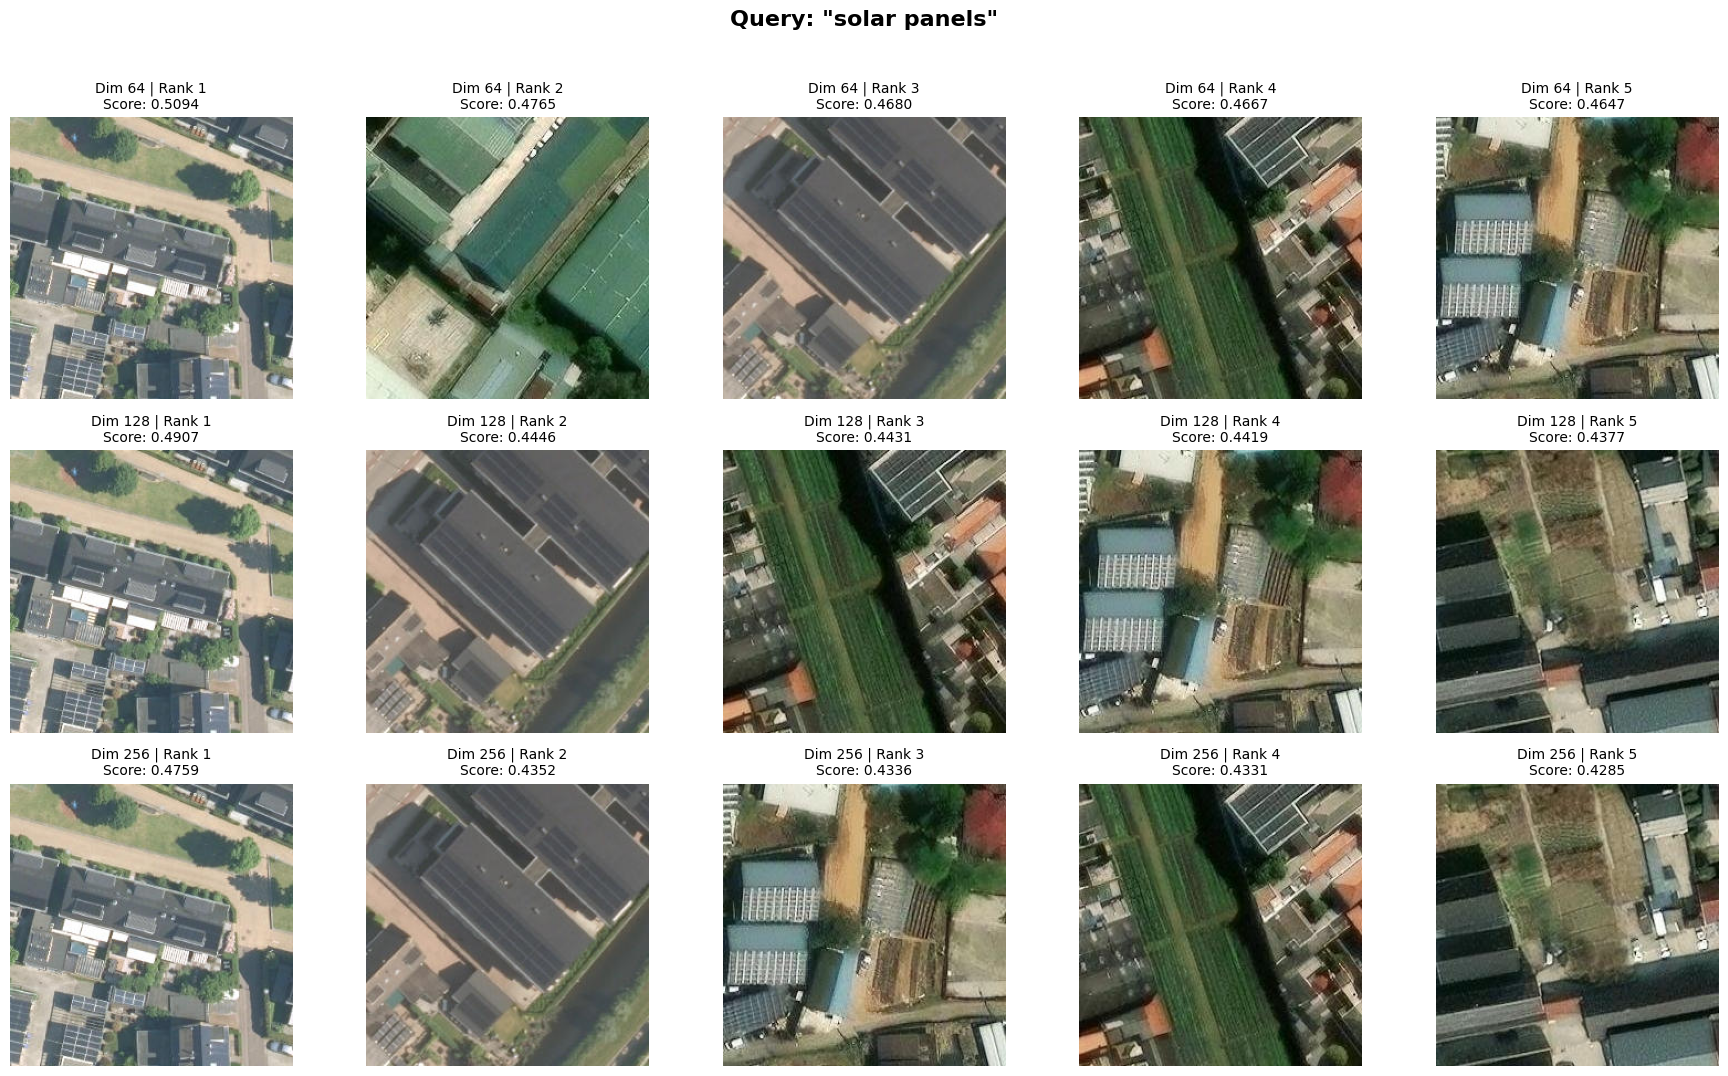

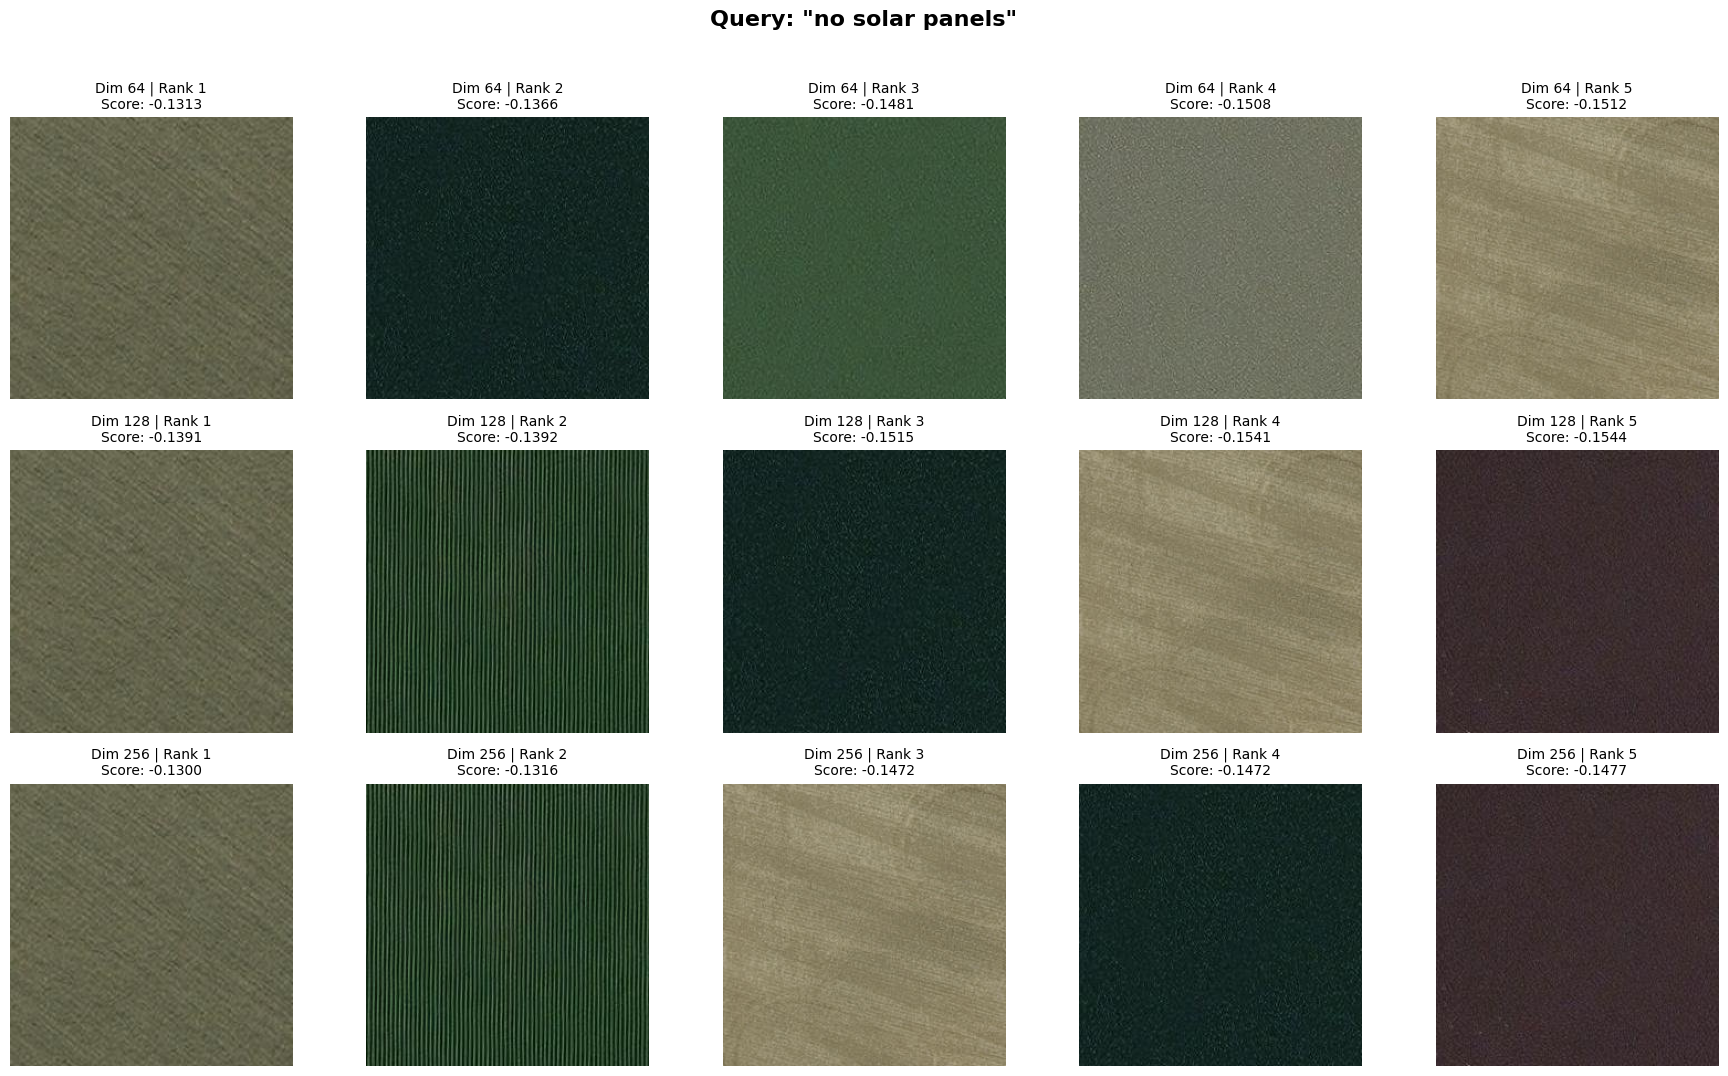

In [6]:
# ==============================================================================
# Cell 5: Truncation, L2 Re-Normalization, & Multi-Dimension Retrieval Plot
# ==============================================================================
import matplotlib.pyplot as plt
import matplotlib as mpl

# Set up global font fallbacks for Chinese, Hindi, and Latin
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = [
    'DejaVu Sans',
    'Noto Sans CJK SC',
    'Noto Sans CJK JP',
    'Noto Sans Devanagari',
    'SimHei',
    'Arial Unicode MS'
]
mpl.rcParams['axes.unicode_minus'] = False

DIMENSIONS = [64, 128, 256]
TOP_K = 5

def get_normalized_slice(embeddings: np.ndarray, dim: int) -> np.ndarray:
    """Slices vector to target dimension and re-normalizes L2 unit length."""
    sub_emb = embeddings[:, :dim]
    norms = np.linalg.norm(sub_emb, axis=1, keepdims=True)
    norms[norms == 0] = 1e-12  # Avoid division by zero
    return sub_emb / norms

# Precompute similarity matrices for 64, 128, and 256 dims
similarity_matrices = {}
for d in DIMENSIONS:
    txt_sliced = get_normalized_slice(raw_text_embeddings, d)
    img_sliced = get_normalized_slice(raw_image_embeddings, d)
    similarity_matrices[d] = txt_sliced @ img_sliced.T

# Plot comparative retrieval results side-by-side
for q_idx, query in enumerate(QUERIES):
    fig, axes = plt.subplots(len(DIMENSIONS), TOP_K, figsize=(18, 3.5 * len(DIMENSIONS)))
    fig.suptitle(f'Query: "{query}"', fontsize=16, fontweight="bold", y=1.02)

    for row_idx, d in enumerate(DIMENSIONS):
        scores = similarity_matrices[d][q_idx]
        top_k_indices = np.argsort(-scores)[:TOP_K]

        for col_idx, img_idx in enumerate(top_k_indices):
            score = scores[img_idx]
            ax = axes[row_idx, col_idx] if len(DIMENSIONS) > 1 else axes[col_idx]

            ax.imshow(raw_pil_images[img_idx])
            ax.set_title(f"Dim {d} | Rank {col_idx+1}\nScore: {score:.4f}", fontsize=10)
            ax.axis("off")

    plt.tight_layout()
    plt.show()

---

In [7]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np
import torch
import torch.nn.functional as F

# --- Step 1: Set up a font that supports multilingual characters (Hindi/Mandarin) ---
# We check for common system fonts supporting CJK/Devanagari, falling back gracefully.
available_fonts = {f.name for f in fm.fontManager.ttflist}

# Pick the best available unicode font depending on the OS
multilingual_font = None
for candidate in ['Noto Sans', 'Arial Unicode MS', 'Microsoft YaHei', 'Mangal', 'DejaVu Sans']:
    if candidate in available_fonts:
        multilingual_font = candidate
        break

# Configure matplotlib to use this font globally for text rendering
if multilingual_font:
    plt.rcParams['font.family'] = 'sans-serif'
    plt.rcParams['font.sans-serif'] = [multilingual_font, 'DejaVu Sans']

# Fix for minus signs rendering as boxes in some fonts
plt.rcParams['axes.unicode_minus'] = False


def show_top5(query):
    with torch.no_grad():
        enc = tokenizer(
            [query],
            padding=True,
            truncation=True,
            max_length=model.transformer.context_length,
            return_tensors="pt",
        )
        tokens = {k: v.to(device) for k, v in enc.items() if k in ("input_ids", "attention_mask")}

        text_embeddings = model.encode_text(tokens)
        raw_text_embeddings = F.normalize(text_embeddings, dim=-1).cpu().numpy()

    DIMENSIONS = [64, 128, 256]
    TOP_K = 5

    def get_normalized_slice(embeddings: np.ndarray, dim: int) -> np.ndarray:
        """Slices vector to target dimension and re-normalizes L2 unit length."""
        sub_emb = embeddings[:, :dim]
        norms = np.linalg.norm(sub_emb, axis=1, keepdims=True)
        norms[norms == 0] = 1e-12  # Avoid division by zero
        return sub_emb / norms

    # Precompute similarity matrices for 64, 128, and 256 dims
    similarity_matrices = {}
    for d in DIMENSIONS:
        txt_sliced = get_normalized_slice(raw_text_embeddings, d)
        img_sliced = get_normalized_slice(raw_image_embeddings, d)
        similarity_matrices[d] = txt_sliced @ img_sliced.T

    # Plot comparative retrieval results side-by-side
    fig, axes = plt.subplots(len(DIMENSIONS), TOP_K, figsize=(18, 3.5 * len(DIMENSIONS)))

    # Explicitly pass fontproperties or rely on rcParams set above
    fig.suptitle(f'Query: "{query}"', fontsize=16, fontweight="bold", y=1.02)

    for row_idx, d in enumerate(DIMENSIONS):
        scores = similarity_matrices[d][0]
        top_k_indices = np.argsort(-scores)[:TOP_K]

        for col_idx, img_idx in enumerate(top_k_indices):
            score = scores[img_idx]
            ax = axes[row_idx, col_idx] if len(DIMENSIONS) > 1 else axes[col_idx]

            ax.imshow(raw_pil_images[img_idx])
            ax.set_title(f"Dim {d} | Rank {col_idx+1}\nScore: {score:.4f}", fontsize=10)
            ax.axis("off")

    plt.tight_layout()
    plt.show()

In [8]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np
import torch
import torch.nn.functional as F

# --- Step 1: Force Matplotlib to find/rebuild font cache & pick a multilingual font ---
# Clear font cache if it's holding onto old data (safe to run)
try:
    fm._rebuild() # For older matplotlib versions
except AttributeError:
    pass

# Find a reliable unicode font available on your system
font_candidates = [
    'Noto Sans', 'Noto Sans CJK SC', 'Noto Sans Devanagari', 
    'Arial Unicode MS', 'Microsoft YaHei', 'Mangal', 'DejaVu Sans'
]

multilingual_prop = None
available_font_names = {f.name for f in fm.fontManager.ttflist}

for font_name in font_candidates:
    if font_name in available_font_names:
        multilingual_prop = fm.FontProperties(family=font_name, size=16, weight='bold')
        break

# Fallback if none of the specific ones match
if multilingual_prop is None:
    multilingual_prop = fm.FontProperties(size=16, weight='bold')

# Fix for minus signs rendering as boxes
plt.rcParams['axes.unicode_minus'] = False


def show_top5(query):
    with torch.no_grad():
        enc = tokenizer(
            [query],
            padding=True,
            truncation=True,
            max_length=model.transformer.context_length,
            return_tensors="pt",
        )
        tokens = {k: v.to(device) for k, v in enc.items() if k in ("input_ids", "attention_mask")}

        text_embeddings = model.encode_text(tokens)
        raw_text_embeddings = F.normalize(text_embeddings, dim=-1).cpu().numpy()

    DIMENSIONS = [64, 128, 256]
    TOP_K = 5

    def get_normalized_slice(embeddings: np.ndarray, dim: int) -> np.ndarray:
        """Slices vector to target dimension and re-normalizes L2 unit length."""
        sub_emb = embeddings[:, :dim]
        norms = np.linalg.norm(sub_emb, axis=1, keepdims=True)
        norms[norms == 0] = 1e-12  # Avoid division by zero
        return sub_emb / norms

    # Precompute similarity matrices for 64, 128, and 256 dims
    similarity_matrices = {}
    for d in DIMENSIONS:
        txt_sliced = get_normalized_slice(raw_text_embeddings, d)
        img_sliced = get_normalized_slice(raw_image_embeddings, d)
        similarity_matrices[d] = txt_sliced @ img_sliced.T

    # Plot comparative retrieval results side-by-side
    fig, axes = plt.subplots(len(DIMENSIONS), TOP_K, figsize=(18, 3.5 * len(DIMENSIONS)))

    # Explicitly pass fontproperties so it forces the correct font rendering on the title
    fig.suptitle(f'Query: "{query}"', fontproperties=multilingual_prop, y=1.02)

    for row_idx, d in enumerate(DIMENSIONS):
        scores = similarity_matrices[d][0]
        top_k_indices = np.argsort(-scores)[:TOP_K]

        for col_idx, img_idx in enumerate(top_k_indices):
            score = scores[img_idx]
            ax = axes[row_idx, col_idx] if len(DIMENSIONS) > 1 else axes[col_idx]

            ax.imshow(raw_pil_images[img_idx])
            ax.set_title(f"Dim {d} | Rank {col_idx+1}\nScore: {score:.4f}", fontsize=10)
            ax.axis("off")

    plt.tight_layout()
    plt.show()

In [9]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

print(mpl.__version__)            # need >= 3.6 for per-glyph font fallback

# optional, no-root route: register font files by path
# for p in ["/path/NotoSansCJK-Bold.ttc", "/path/NotoSansDevanagari-Bold.ttf"]:
#     fm.fontManager.addfont(p)

# rebuild the font cache so newly installed fonts are seen (replaces fm._rebuild())
fm._load_fontmanager(try_read_cache=False)

available = {f.name for f in fm.fontManager.ttflist}
print(sorted(n for n in available if any(k in n for k in ("CJK", "Devanagari", "Noto"))))

# order = fallback order, glyph by glyph. Cantonese -> Traditional/HK Han variant first.
wanted = ["Noto Sans", "Noto Sans CJK HK", "Noto Sans CJK TC", "Noto Sans CJK SC",
          "Noto Sans Devanagari", "Mangal", "Arial Unicode MS", "DejaVu Sans"]
families = [f for f in wanted if f in available] or ["DejaVu Sans"]
multilingual_prop = fm.FontProperties(family=families, size=16, weight="bold")

plt.rcParams["axes.unicode_minus"] = False


def show_top5(query):
    with torch.no_grad():
        enc = tokenizer(
            [query],
            padding=True,
            truncation=True,
            max_length=model.transformer.context_length,
            return_tensors="pt",
        )
        tokens = {k: v.to(device) for k, v in enc.items() if k in ("input_ids", "attention_mask")}

        text_embeddings = model.encode_text(tokens)
        raw_text_embeddings = F.normalize(text_embeddings, dim=-1).cpu().numpy()

    DIMENSIONS = [64, 128, 256]
    TOP_K = 5

    def get_normalized_slice(embeddings: np.ndarray, dim: int) -> np.ndarray:
        """Slices vector to target dimension and re-normalizes L2 unit length."""
        sub_emb = embeddings[:, :dim]
        norms = np.linalg.norm(sub_emb, axis=1, keepdims=True)
        norms[norms == 0] = 1e-12  # Avoid division by zero
        return sub_emb / norms

    # Precompute similarity matrices for 64, 128, and 256 dims
    similarity_matrices = {}
    for d in DIMENSIONS:
        txt_sliced = get_normalized_slice(raw_text_embeddings, d)
        img_sliced = get_normalized_slice(raw_image_embeddings, d)
        similarity_matrices[d] = txt_sliced @ img_sliced.T

    # Plot comparative retrieval results side-by-side
    fig, axes = plt.subplots(len(DIMENSIONS), TOP_K, figsize=(18, 3.5 * len(DIMENSIONS)))

    # Explicitly pass fontproperties so it forces the correct font rendering on the title
    fig.suptitle(f'Query: "{query}"', fontproperties=multilingual_prop, y=1.02)

    for row_idx, d in enumerate(DIMENSIONS):
        scores = similarity_matrices[d][0]
        top_k_indices = np.argsort(-scores)[:TOP_K]

        for col_idx, img_idx in enumerate(top_k_indices):
            score = scores[img_idx]
            ax = axes[row_idx, col_idx] if len(DIMENSIONS) > 1 else axes[col_idx]

            ax.imshow(raw_pil_images[img_idx])
            ax.set_title(f"Dim {d} | Rank {col_idx+1}\nScore: {score:.4f}", fontsize=10)
            ax.axis("off")

    plt.tight_layout()
    plt.show()

3.10.9
[]


In [10]:
import pandas as pd

df = pd.read_parquet(rf"/data/susanket/vlm/images3/caption-09.parquet")

In [11]:
df.columns

Index(['file_name', 'status', 'error', 'summary', 'dense_caption',
       'key_elements', 'cf_dense_caption', 'cf_edits', 'cf_status',
       'translated_col', 'translated_lang'],
      dtype='str')